# 📦 Inventory Analysis Workshop — Retail Stock Control
**Run in Google Colab · No installation · Python**

### The story
You are an inventory analyst at **SmartMart**, a retail chain. The stock room holds **200 items** across **5 categories**, **8 stock locations** and **7 suppliers**.
Nobody has time to check every shelf, so your manager asks:

1. 📊 **How healthy is our stock overall?**
2. 🏬 **Which categories and locations have problems?**
3. 🛒 **What must we reorder now, and from which supplier?**
4. 💰 **Where is our money tied up?**
5. ⚡ **Can we catch a stock-out the moment a sale happens?**

### The data
`inventory_master.csv` has only what a real stock register records:

| item_id | sku | item_name | category | unit | quantity_on_hand | unit_price_inr | reorder_level | location | supplier |
|---|---|---|---|---|---|---|---|---|---|

👉 **There is no stock status, stock value or reorder cost column.** Our job is to **create them** using Python.

### How to run
Press **Shift + Enter** on each cell from top to bottom. Run **Step 0** first to upload the CSV.

## Step 0 — Upload the dataset
Run this cell and click **Choose Files** → select `inventory_master.csv`.

In [2]:
import os
CSV = "inventory_master.csv"
if os.path.exists(CSV):
    print(f"✔ {CSV} found — ready to go")
else:
    from google.colab import files
    files.upload()
    print("✔ Upload complete" if os.path.exists(CSV) else "✖ Please upload a file named exactly inventory_master.csv")

✔ inventory_master.csv found — ready to go


## Step 1 — Load the tools
Colab already has everything: pandas for tables, matplotlib and seaborn for charts.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
ORDER  = ["Out of Stock", "Low Stock", "Healthy", "Overstocked"]
COLORS = {"Out of Stock": "#d64545", "Low Stock": "#e8a33d", "Healthy": "#2e9d5b", "Overstocked": "#3b7dd8"}
print("✔ Tools ready")

✔ Tools ready


## Step 2 — Look at the stock register

In [4]:
df = pd.read_csv(CSV)
print("Number of items:", len(df))
print("Categories:", ", ".join(df["category"].unique()))
print("Locations :", ", ".join(sorted(df["location"].unique())))
print("Suppliers :", ", ".join(sorted(df["supplier"].unique())))
print("Missing values:", int(df.isna().sum().sum()), "| Duplicate SKUs:", int(df["sku"].duplicated().sum()))
df.head(10)

Number of items: 200
Categories: Electronics, Grocery, Stationery, Hardware, Clothing
Locations : branch 1, branch 2, branch 3, godown, main store, shop floor, warehouse A, warehouse B
Suppliers : Annapoorna Wholesale, Coromandel Traders, Kaveri Distributors, Lakshmi Agencies, Metro Supplies, Sri Balaji Traders, Tech Hub Pvt Ltd
Missing values: 0 | Duplicate SKUs: 0


,item_id,sku,item_name,category,unit,quantity_on_hand,unit_price_inr,reorder_level,location,supplier
0,ITM001,ELE-0001,laptop,Electronics,units,2,78823,5,warehouse B,Annapoorna Wholesale
1,ITM002,ELE-0002,mouse,Electronics,pieces,4,476,20,branch 2,Metro Supplies
2,ITM003,ELE-0003,keyboard,Electronics,pieces,30,2816,50,warehouse B,Kaveri Distributors
3,ITM004,ELE-0004,monitor,Electronics,units,36,16593,8,branch 2,Sri Balaji Traders
4,ITM005,ELE-0005,usb cable,Electronics,pieces,37,314,20,main store,Lakshmi Agencies
5,ITM006,ELE-0006,headphones,Electronics,pieces,13,2882,20,shop floor,Annapoorna Wholesale
6,ITM007,ELE-0007,webcam,Electronics,pieces,36,1444,10,shop floor,Metro Supplies
7,ITM008,ELE-0008,wifi router,Electronics,units,29,3398,8,branch 3,Annapoorna Wholesale
8,ITM009,ELE-0009,phone charger,Electronics,pieces,10,1476,20,godown,Lakshmi Agencies
9,ITM010,ELE-0010,hard disk,Electronics,units,9,5994,5,warehouse B,Sri Balaji Traders


👉 Point out that there is **no status column** yet. Also note the prices: a laptop costs ₹78,823 while a pen costs a few rupees.

## Step 3 — How does the computer judge stock?
We compare **quantity on hand** with the **reorder level** (the minimum we want on the shelf). Run this and watch the status change.

**Rule we will use:**
🔴 quantity = 0 → **Out of Stock** · 🟠 quantity ≤ reorder level → **Low Stock** · 🔵 quantity > 3 × reorder level → **Overstocked** · otherwise 🟢 **Healthy**

In [5]:
def classify(qty, reorder):
    if qty == 0:
        return "Out of Stock"
    if qty <= reorder:
        return "Low Stock"
    if qty > 3 * reorder:
        return "Overstocked"
    return "Healthy"

examples = [(0, 10), (4, 10), (10, 10), (25, 10), (30, 10), (31, 10)]
for qty, reorder in examples:
    print(f"quantity {qty:>3}   reorder level {reorder:>3}   →   {classify(qty, reorder)}")

quantity   0   reorder level  10   →   Out of Stock
quantity   4   reorder level  10   →   Low Stock
quantity  10   reorder level  10   →   Low Stock
quantity  25   reorder level  10   →   Healthy
quantity  30   reorder level  10   →   Healthy
quantity  31   reorder level  10   →   Overstocked


## Step 4 — Create the new columns (status, value, reorder cost)
We refill a low item up to **2 × its reorder level** (our assumption — change `TARGET` later and see what happens).

In [6]:
df["item_name"] = df["item_name"].str.title()
df["location"]  = df["location"].str.title()

TARGET = 2   # refill up to 2 x reorder level

df["stock_value"] = df["quantity_on_hand"] * df["unit_price_inr"]
df["stock_ratio"] = (df["quantity_on_hand"] / df["reorder_level"]).round(2)
df["status"]      = [classify(q, r) for q, r in zip(df["quantity_on_hand"], df["reorder_level"])]

needs_order = df["status"].isin(["Low Stock", "Out of Stock"])
df["order_qty"]     = np.where(needs_order, TARGET * df["reorder_level"] - df["quantity_on_hand"], 0)
df["reorder_cost"]  = df["order_qty"] * df["unit_price_inr"]
df["excess_qty"]    = (df["quantity_on_hand"] - 3 * df["reorder_level"]).clip(lower=0)
df["excess_value"]  = df["excess_qty"] * df["unit_price_inr"]

df[["item_name", "category", "quantity_on_hand", "reorder_level", "status", "stock_value", "order_qty"]].head(10)

,item_name,category,quantity_on_hand,reorder_level,status,stock_value,order_qty
0,Laptop,Electronics,2,5,Low Stock,157646,8
1,Mouse,Electronics,4,20,Low Stock,1904,36
2,Keyboard,Electronics,30,50,Low Stock,84480,70
3,Monitor,Electronics,36,8,Overstocked,597348,0
4,Usb Cable,Electronics,37,20,Healthy,11618,0
5,Headphones,Electronics,13,20,Low Stock,37466,27
6,Webcam,Electronics,36,10,Overstocked,51984,0
7,Wifi Router,Electronics,29,8,Overstocked,98542,0
8,Phone Charger,Electronics,10,20,Low Stock,14760,30
9,Hard Disk,Electronics,9,5,Healthy,53946,0


✅ New columns appeared: **stock_value**, **stock_ratio**, **status**, **order_qty**, **reorder_cost**, **excess_value**. All 200 items judged in under a second.

## Step 5 — Q1: How healthy is our stock overall?

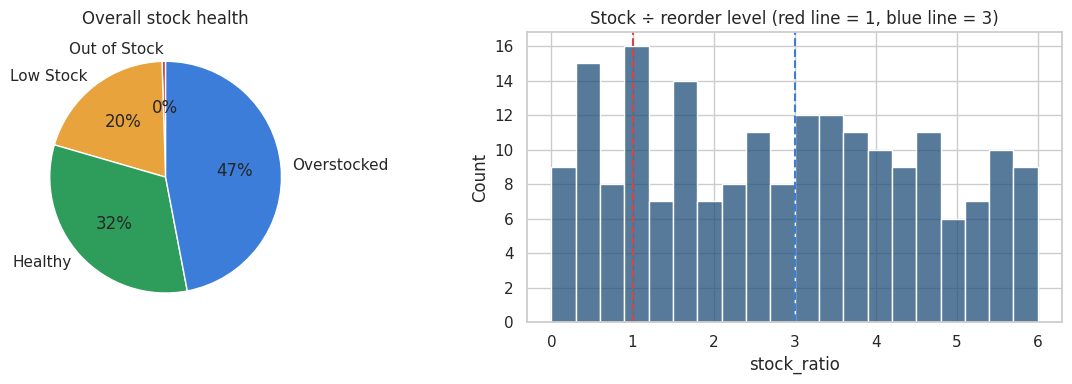

status
Out of Stock     1
Low Stock       40
Healthy         65
Overstocked     94
Name: count, dtype: int64

Total stock value: ₹10,295,341


In [7]:
counts = df["status"].value_counts().reindex(ORDER).fillna(0)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].pie(counts, labels=counts.index, colors=[COLORS[s] for s in counts.index], autopct="%1.0f%%", startangle=90)
ax[0].set_title("Overall stock health")
sns.histplot(df["stock_ratio"], bins=20, color="#1f4e79", ax=ax[1])
ax[1].axvline(1, color="#d64545", ls="--"); ax[1].axvline(3, color="#3b7dd8", ls="--")
ax[1].set_title("Stock ÷ reorder level (red line = 1, blue line = 3)")
plt.tight_layout(); plt.show()
print(counts.astype(int))
print(f"\nTotal stock value: ₹{df.stock_value.sum():,.0f}")

💡 Almost half the items are **Overstocked** and about one in five needs a reorder. Both are problems — one wastes money, the other loses sales.

## Step 6 — Q2: Which categories and locations have problems?

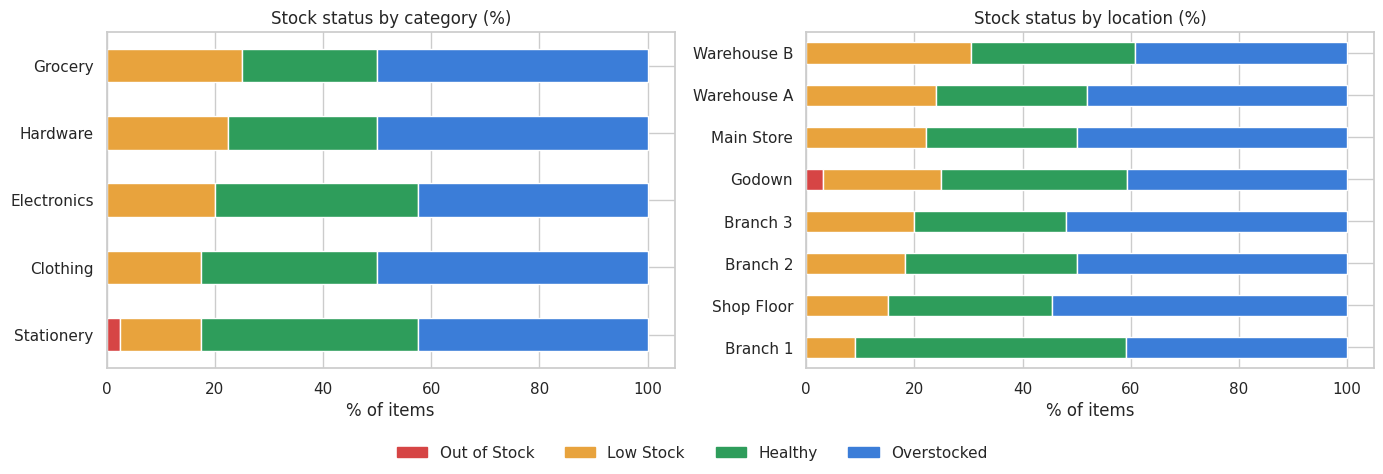

Stock value by category (₹ lakh):
category
Electronics    46.3
Clothing       30.3
Hardware       12.9
Grocery         7.5
Stationery      5.9
Name: stock_value, dtype: float64


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for a, col in zip(ax, ["category", "location"]):
    t = pd.crosstab(df[col], df["status"], normalize="index").reindex(columns=ORDER, fill_value=0) * 100
    t = t.sort_values("Low Stock")
    t.plot(kind="barh", stacked=True, color=[COLORS[s] for s in ORDER], ax=a, legend=False)
    a.set_title(f"Stock status by {col} (%)"); a.set_xlabel("% of items"); a.set_ylabel("")
handles = [plt.Rectangle((0, 0), 1, 1, color=COLORS[s]) for s in ORDER]
fig.legend(handles, ORDER, loc="lower center", ncol=4, frameon=False)
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

print("Stock value by category (₹ lakh):")
print((df.groupby("category")["stock_value"].sum() / 1e5).round(1).sort_values(ascending=False))

💡 Compare the **orange** share (low stock) across bars. Which category or location runs short most often?

## Step 7 — Q3: What must we reorder, and from which supplier?
Only **Low Stock** and **Out of Stock** items need ordering. We sort them by urgency (lowest stock ÷ reorder level first).

Items to reorder: 41   |   Estimated cost: ₹1,762,043



,item_name,category,quantity_on_hand,reorder_level,order_qty,supplier,reorder_cost
115,Pen Stand,Stationery,0,10,20,Metro Supplies,3740
18,Card Reader,Electronics,1,20,39,Annapoorna Wholesale,15522
186,Leggings,Clothing,1,20,39,Metro Supplies,14586
31,Surge Protector,Electronics,1,10,19,Metro Supplies,22021
134,Spirit Level,Hardware,1,10,19,Metro Supplies,4161
54,Raw Rice,Grocery,2,20,38,Metro Supplies,1900
172,Formal Shirt,Clothing,3,20,37,Kaveri Distributors,27195
1,Mouse,Electronics,4,20,36,Metro Supplies,17136
150,Wood Adhesive,Hardware,4,15,26,Coromandel Traders,8658
176,Kurta,Clothing,9,30,51,Metro Supplies,41157


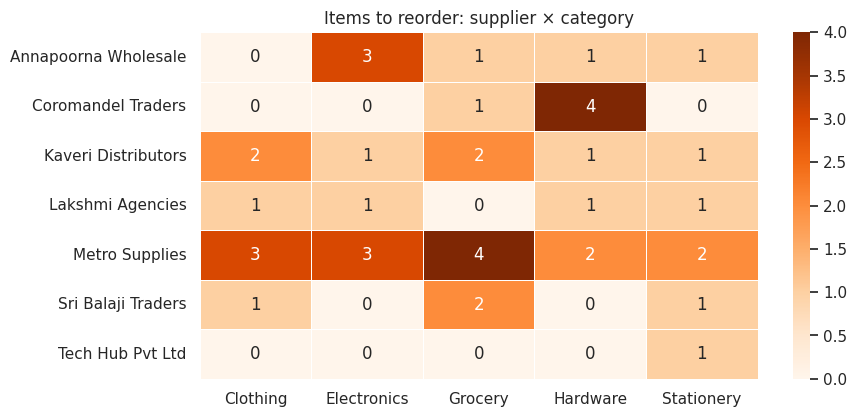

Order value per supplier (₹):
supplier
Annapoorna Wholesale    736055
Metro Supplies          376378
Kaveri Distributors     326046
Coromandel Traders      153189
Sri Balaji Traders      113311
Lakshmi Agencies         56864
Tech Hub Pvt Ltd           200
Name: reorder_cost, dtype: int64


In [9]:
reorder = df[needs_order].sort_values(["stock_ratio", "reorder_cost"], ascending=[True, False])
cols = ["item_name", "category", "quantity_on_hand", "reorder_level", "order_qty", "supplier", "reorder_cost"]
print(f"Items to reorder: {len(reorder)}   |   Estimated cost: ₹{reorder.reorder_cost.sum():,.0f}\n")
display(reorder[cols].head(15))

heat = pd.crosstab(reorder["supplier"], reorder["category"])
plt.figure(figsize=(9, 4.5))
sns.heatmap(heat, annot=True, fmt="d", cmap="Oranges", linewidths=.5)
plt.title("Items to reorder: supplier × category"); plt.ylabel(""); plt.xlabel(""); plt.show()

print("Order value per supplier (₹):")
print(reorder.groupby("supplier")["reorder_cost"].sum().round(0).sort_values(ascending=False).astype(int))

💡 **Group orders by supplier** — one purchase order per supplier is cheaper than 41 separate ones. The darkest cell shows which supplier you depend on for which category.

## Step 8 — Q4: Where is our money tied up?

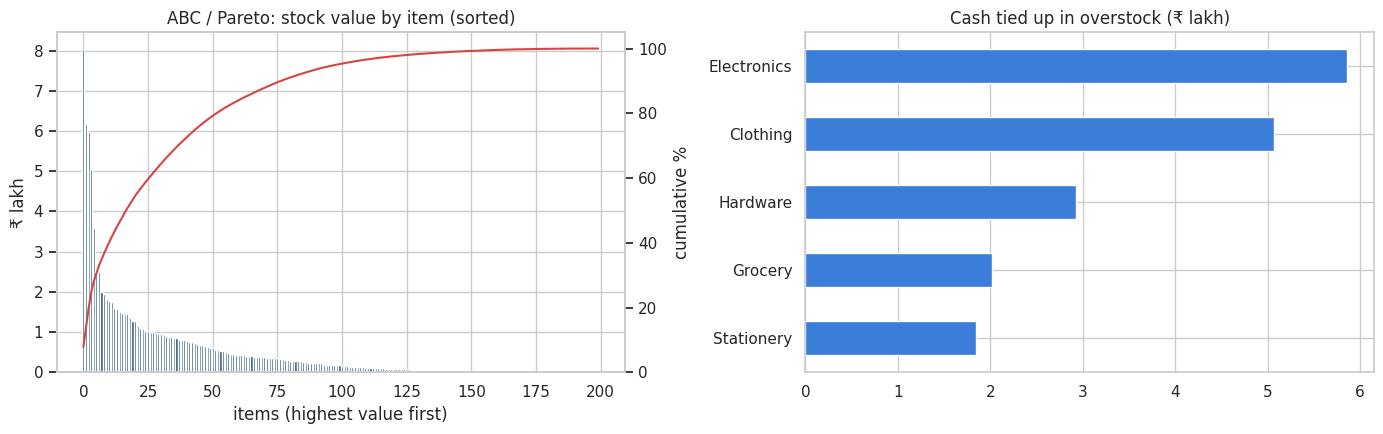

class
A     37
B     40
C    123
Name: items per class, dtype: int64

Excess stock above 3 x reorder level is worth ₹1,772,483


,item_name,category,quantity_on_hand,unit_price_inr,stock_value,class
0,Smartphone,Electronics,15,53681,805215,A
1,Tablet,Electronics,18,34283,617094,A
2,Monitor,Electronics,36,16593,597348,A
3,Saree,Clothing,93,5431,505083,A
4,Jacket,Clothing,81,4418,357858,A
5,Socket Kit,Hardware,177,1419,251163,A
6,Spanner Kit,Hardware,110,2268,249480,A
7,Bluetooth Speaker,Electronics,50,4002,200100,A


In [10]:
abc = df.sort_values("stock_value", ascending=False).reset_index(drop=True)
abc["cum_pct"] = abc["stock_value"].cumsum() / abc["stock_value"].sum() * 100
abc["class"] = pd.cut(abc["cum_pct"], [0, 70, 90, 100.01], labels=["A", "B", "C"])

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].bar(range(len(abc)), abc["stock_value"] / 1e5, color="#1f4e79")
ax2 = ax[0].twinx(); ax2.plot(abc["cum_pct"], color="#d64545"); ax2.set_ylim(0, 105); ax2.grid(False)
ax[0].set_title("ABC / Pareto: stock value by item (sorted)"); ax[0].set_xlabel("items (highest value first)")
ax[0].set_ylabel("₹ lakh"); ax2.set_ylabel("cumulative %")

ex = (df.groupby("category")["excess_value"].sum() / 1e5).sort_values()
ex.plot(kind="barh", color="#3b7dd8", ax=ax[1])
ax[1].set_title("Cash tied up in overstock (₹ lakh)"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

print(abc["class"].value_counts().sort_index().rename("items per class"))
print(f"\nExcess stock above 3 x reorder level is worth ₹{df.excess_value.sum():,.0f}")
display(abc.head(8)[["item_name", "category", "quantity_on_hand", "unit_price_inr", "stock_value", "class"]])

💡 Just **37 items (the A class)** hold 70% of the value — guard these first. The right chart shows how much cash sits in stock you do not need yet.

## Step 9 — Read the real items: most urgent and most overstocked

In [11]:
pd.set_option("display.max_colwidth", 60)
print("🚨 Most urgent (lowest stock ÷ reorder level)")
display(df.sort_values("stock_ratio").head(5)[["item_name", "location", "quantity_on_hand", "reorder_level", "supplier"]])
print("💤 Most cash tied up in excess stock")
display(df.nlargest(5, "excess_value")[["item_name", "location", "quantity_on_hand", "reorder_level", "excess_value"]])

🚨 Most urgent (lowest stock ÷ reorder level)


,item_name,location,quantity_on_hand,reorder_level,supplier
115,Pen Stand,Godown,0,10,Metro Supplies
18,Card Reader,Main Store,1,20,Annapoorna Wholesale
186,Leggings,Main Store,1,20,Metro Supplies
54,Raw Rice,Branch 3,2,20,Metro Supplies
134,Spirit Level,Warehouse B,1,10,Metro Supplies


💤 Most cash tied up in excess stock


,item_name,location,quantity_on_hand,reorder_level,excess_value
3,Monitor,Branch 2,36,8,199116
136,Socket Kit,Shop Floor,177,30,123453
162,Jacket,Shop Floor,81,20,92778
25,Ssd Drive,Branch 3,27,5,77976
19,Hdmi Cable,Branch 1,273,50,64944


Always read real examples to check the numbers make sense.

## Step 10 — Where does a simple rule get it wrong?
Rules are fast but blunt. Two weak spots to discuss:

In [12]:
print("1) 'Healthy' items that are one sale away from Low Stock (ratio between 1.0 and 1.25)")
display(df[(df.stock_ratio > 1) & (df.stock_ratio <= 1.25)][["item_name", "quantity_on_hand", "reorder_level", "status"]])

print("2) The rule treats every item the same — but a missing laptop hurts more than a missing paper clip")
print("   Ordered by ratio vs ordered by money:")
a = reorder.head(5)[["item_name", "stock_ratio", "reorder_cost"]].assign(ranked_by="lowest ratio")
b = reorder.nlargest(5, "reorder_cost")[["item_name", "stock_ratio", "reorder_cost"]].assign(ranked_by="highest cost")
display(pd.concat([a, b]))

1) 'Healthy' items that are one sale away from Low Stock (ratio between 1.0 and 1.25)


,item_name,quantity_on_hand,reorder_level,status
16,Earphones,35,30,Healthy
41,Wheat Flour,33,30,Healthy
45,Tea Powder,54,50,Healthy
100,Paper Clips,21,20,Healthy
102,Push Pins,61,50,Healthy
107,Graph Book,32,30,Healthy
139,Washers,53,50,Healthy
189,School Bag,21,20,Healthy


2) The rule treats every item the same — but a missing laptop hurts more than a missing paper clip
   Ordered by ratio vs ordered by money:


,item_name,stock_ratio,reorder_cost,ranked_by
115,Pen Stand,0.00,3740,lowest ratio
18,Card Reader,0.05,15522,lowest ratio
186,Leggings,0.05,14586,lowest ratio
31,Surge Protector,0.10,22021,lowest ratio
134,Spirit Level,0.10,4161,lowest ratio
0,Laptop,0.40,630584,highest cost
2,Keyboard,0.60,197120,highest cost
26,Ram Module,0.65,124362,highest cost
152,Plywood Sheet,0.64,117980,highest cost
131,Copper Wire,0.40,109520,highest cost


❓ **Ask the audience:** Which five would you order first — by urgency or by money? (Bonus Step 13 tries a smarter ML method.)

## Step 11 — ⚡ Q5: Real-time — check an item the moment it sells
Choose an item, enter the units sold, and click **Check**. The tool tells you the new stock, status and what to order.

In [13]:
def check_stock(item, units_sold):
    row = df[df["item_name"] == item].iloc[0]
    new_qty = max(int(row.quantity_on_hand) - int(units_sold), 0)
    status = classify(new_qty, row.reorder_level)
    emoji = {"Out of Stock": "🔴", "Low Stock": "🟠", "Healthy": "🟢", "Overstocked": "🔵"}[status]
    order = int(TARGET * row.reorder_level - new_qty) if status in ("Out of Stock", "Low Stock") else 0
    if order:
        action = f"🚨 ALERT — order {order} {row.unit} from {row.supplier} (≈ ₹{order * row.unit_price_inr:,.0f})"
    elif status == "Overstocked":
        action = "Pause purchasing — stock is more than 3x the reorder level"
    else:
        action = "No action needed"
    return dict(item=item, new_qty=new_qty, reorder_level=int(row.reorder_level), status=status,
                emoji=emoji, color=COLORS[status], action=action, location=row.location)

print(check_stock("Laptop", 1))
print(check_stock("Wheat Flour", 5))

{'item': 'Laptop', 'new_qty': 1, 'reorder_level': 5, 'status': 'Low Stock', 'emoji': '🟠', 'color': '#e8a33d', 'action': '🚨 ALERT — order 9 units from Annapoorna Wholesale (≈ ₹709,407)', 'location': 'Warehouse B'}
{'item': 'Wheat Flour', 'new_qty': 28, 'reorder_level': 30, 'status': 'Low Stock', 'emoji': '🟠', 'color': '#e8a33d', 'action': '🚨 ALERT — order 32 kg from Metro Supplies (≈ ₹1,152)', 'location': 'Branch 1'}


Now the interactive box 👇

In [14]:
import ipywidgets as widgets
from IPython.display import display, HTML

pick = widgets.Dropdown(options=sorted(df["item_name"]), description="Item:")
qty  = widgets.IntText(value=1, description="Units sold:")
btn  = widgets.Button(description="Check", button_style="success", icon="search")
out  = widgets.Output()

def on_click(_):
    with out:
        out.clear_output()
        r = check_stock(pick.value, qty.value)
        display(HTML(f'''<div style="border-left:8px solid {r["color"]};padding:10px 16px;margin-top:6px;background:#f7f9fa;color:#222;border-radius:6px">
            <div style="font-size:22px"><b>{r["emoji"]} {r["status"]}</b></div>
            <div>{r["item"]} @ {r["location"]} — stock now <b>{r["new_qty"]}</b> (reorder level {r["reorder_level"]})</div>
            <div>Action: <b>{r["action"]}</b></div></div>'''))

btn.on_click(on_click)
display(pick, qty, btn, out)

Dropdown(description='Item:', options=('A4 Paper', 'Baby Romper', 'Ball Pen', 'Basmati Rice', 'Bedsheet', 'Bel…

IntText(value=1, description='Units sold:')

Button(button_style='success', description='Check', icon='search', style=ButtonStyle())

Output()

## Step 12 — ⚡ Live sales feed (simulation)
Pretend sales are happening at the counter every second. Watch the stock and alerts update live.

In [15]:
import time
sales = [("Wheat Flour", 5), ("Smart Watch", 5), ("Paper Clips", 3), ("Hammer", 1),
         ("Iron Box", 4), ("Notebook", 2), ("Tea Powder", 10), ("Earphones", 2)]

live = df.set_index("item_name")["quantity_on_hand"].copy()
tally = {s: 0 for s in ORDER}
for i, (item, n) in enumerate(sales, 1):
    live_row = df[df["item_name"] == item].iloc[0]
    new_qty = max(int(live[item]) - n, 0)
    live[item] = new_qty
    status = classify(new_qty, live_row.reorder_level)
    tally[status] += 1
    alert = "   🚨 ALERT — reorder" if status in ("Low Stock", "Out of Stock") else ""
    print(f"[{i}] sold {n:>2} x {item:<13} → stock {new_qty:>3} | {status:<12}{alert}")
    print(f"     Live count →  🔴 {tally['Out of Stock']}   🟠 {tally['Low Stock']}   🟢 {tally['Healthy']}   🔵 {tally['Overstocked']}\n")
    time.sleep(1.5)

[1] sold  5 x Wheat Flour   → stock  28 | Low Stock      🚨 ALERT — reorder
     Live count →  🔴 0   🟠 1   🟢 0   🔵 0

[2] sold  5 x Smart Watch   → stock  26 | Healthy     
     Live count →  🔴 0   🟠 1   🟢 1   🔵 0

[3] sold  3 x Paper Clips   → stock  18 | Low Stock      🚨 ALERT — reorder
     Live count →  🔴 0   🟠 2   🟢 1   🔵 0

[4] sold  1 x Hammer        → stock  12 | Healthy     
     Live count →  🔴 0   🟠 2   🟢 2   🔵 0

[5] sold  4 x Iron Box      → stock   0 | Out of Stock   🚨 ALERT — reorder
     Live count →  🔴 1   🟠 2   🟢 2   🔵 0

[6] sold  2 x Notebook      → stock  60 | Healthy     
     Live count →  🔴 1   🟠 2   🟢 3   🔵 0

[7] sold 10 x Tea Powder    → stock  44 | Low Stock      🚨 ALERT — reorder
     Live count →  🔴 1   🟠 3   🟢 3   🔵 0

[8] sold  2 x Earphones     → stock  33 | Healthy     
     Live count →  🔴 1   🟠 3   🟢 4   🔵 0



## Step 13 — ⭐ Bonus: a smarter method — machine learning to spot unusual items
Our rules only find **known** problems. **Isolation Forest** is a ready-made ML model that finds items that look **odd** compared with the rest (unusual price, quantity and stock ratio together). No labels are needed.

In [16]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

X = pd.DataFrame({
    "log_price": np.log1p(df["unit_price_inr"]),
    "log_value": np.log1p(df["stock_value"]),
    "stock_ratio": df["stock_ratio"],
})
Xs = StandardScaler().fit_transform(X)
iso = IsolationForest(contamination=0.05, random_state=42)
df["unusual"] = iso.fit_predict(Xs) == -1

print("Items flagged as unusual:", int(df["unusual"].sum()))
display(df[df["unusual"]][["item_name", "category", "quantity_on_hand", "reorder_level", "unit_price_inr", "status"]])
print("Status of flagged vs normal items:")
display(pd.crosstab(df["unusual"], df["status"]))

Items flagged as unusual: 10


,item_name,category,quantity_on_hand,reorder_level,unit_price_inr,status
0,Laptop,Electronics,2,5,78823,Low Stock
3,Monitor,Electronics,36,8,16593,Overstocked
12,Smartphone,Electronics,15,5,53681,Healthy
13,Tablet,Electronics,18,8,34283,Healthy
27,Motherboard,Electronics,13,8,13654,Healthy
81,Ball Pen,Stationery,42,10,7,Overstocked
82,Pencil,Stationery,29,20,10,Healthy
96,Sharpener,Stationery,53,10,14,Overstocked
115,Pen Stand,Stationery,0,10,187,Out of Stock
148,Paint Brush,Hardware,170,30,21,Overstocked


Status of flagged vs normal items:


status,Healthy,Low Stock,Out of Stock,Overstocked
unusual,,,,
False,61,39,0,90
True,4,1,1,4


💬 **Discuss:** The rule says *what is short or excess*; ML says *what looks strange*. Check flagged items by hand — some may be data-entry errors worth fixing.

## Step 14 — Save results for Excel / Power BI / Tableau

In [17]:
out_cols = ["item_id", "sku", "item_name", "category", "unit", "quantity_on_hand", "unit_price_inr", "reorder_level",
            "location", "supplier", "stock_value", "stock_ratio", "status", "order_qty", "reorder_cost", "excess_value", "unusual"]
df[out_cols].to_csv("inventory_analysis.csv", index=False)
reorder[cols].to_csv("reorder_list.csv", index=False)
print("✔ Saved inventory_analysis.csv and reorder_list.csv")
try:
    from google.colab import files
    files.download("inventory_analysis.csv")
    files.download("reorder_list.csv")
except ImportError:
    pass

✔ Saved inventory_analysis.csv and reorder_list.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 🎯 What we did
| Business question | How we answered it |
|---|---|
| How healthy is our stock? | Rule on quantity vs reorder level → pie chart |
| Which categories / locations struggle? | Status % by category and by location |
| What must we reorder, from whom? | Urgency-sorted reorder list, supplier × category heatmap |
| Where is money tied up? | ABC / Pareto chart and overstock value |
| Catch a stock-out instantly? | Real-time checker and live sales feed with alerts |

### 🏋️ Try it yourself
1. Change the **Overstocked** rule from `3 *` to `4 *` in Step 3. How many items change status?
2. Change `TARGET = 2` to `TARGET = 3` in Step 4. How much does the total reorder cost rise?
3. Find which **supplier** has the most overstocked items (hint: copy the Step 6 code, change `location` to `supplier`).
4. Load `inventory_analysis.csv` into Power BI or Tableau and build a dashboard.